In [1]:

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage



# Read dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print(df.head())

In [16]:
# Select numerical columns
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']]
print(X.head())
# Normalize data
sc = StandardScaler()
X = sc.fit_transform(X)


   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95


In [17]:
# Elbow Method
wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)



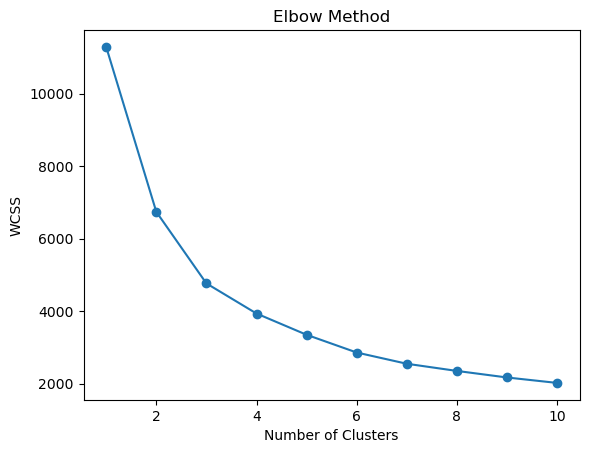

In [18]:
# Plot Elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [19]:
# Apply K-Means (choose K=4)
km = KMeans(n_clusters=4, random_state=42, n_init=10)
df['KMeans_Cluster'] = km.fit_predict(X)

print("K-Means Clusters:")
print(df['KMeans_Cluster'].value_counts())





K-Means Clusters:
KMeans_Cluster
1    930
2    705
3    627
0    561
Name: count, dtype: int64


In [20]:
# Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=4)
df['Hierarchical_Cluster'] = hc.fit_predict(X)

print("\nHierarchical Clusters:")
print(df['Hierarchical_Cluster'].value_counts())


Hierarchical Clusters:
Hierarchical_Cluster
0    934
1    742
2    685
3    462
Name: count, dtype: int64


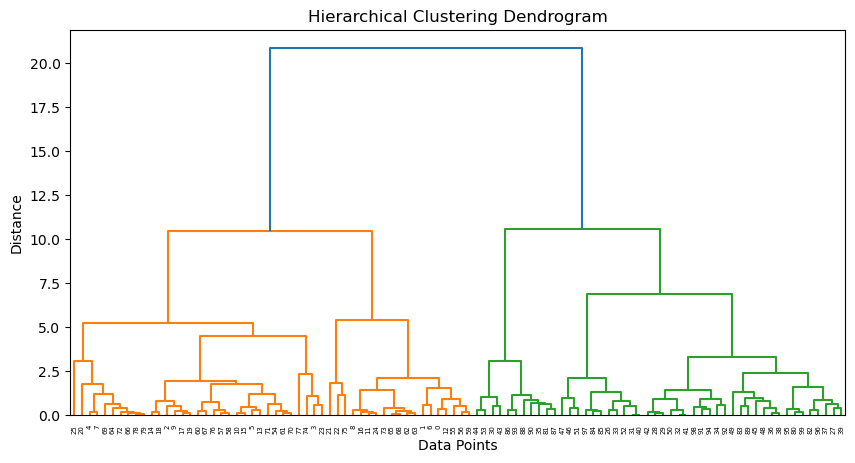

In [8]:
# Draw Dendrogram
plt.figure(figsize=(10, 5))
dendrogram(linkage(X[:100], method='ward'))
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()
